## Data and parameters

We are using the Q1b_NER.csv file that we made in assignment 1. Every row has one recipe and one ingredient so we grouped by Recipe_ID to get each recipe as a set of ingredients, names are changed to lower case and extra spaces removed. The nature basket is all unique ingredients in the data which comes to 12641 and the kitchen basket is the ingredients the cuisine can use at that time, it starts small and grows every epoch.

The real data has 9988 recipes and the average recipe size is 10.00 so we took s = 10. For the primordial cuisine we took 200 recipes since its in the 100-300 range and its easy to get 200 unique recipes. Number of epochs is round(9988/200) = round(49.94) = 50 so each epoch adds about the same number of recipes as the starting cuisine, and recipes per epoch is round(9988/50) = round(199.76) = 200. We used seeds 11, 22, 33, 44 and 55 for the 5 runs so that results can be reproduced.

The kitchen basket size is kept at round(N_I/N_R x NR(t)) so the kitchen to nature basket ratio stays same as the cuisine grows. It starts at 253 and becomes the full nature basket in the last epoch. One problem is that in our data there are more unique ingredients then recipes (ratio around 1.27) because NER gives many slightly different names for the same ingredient, so the starting KB (253) is a bit bigger than NR(t=0) which is 200. So NR(t=0) >> KB is not possible here if we keep the ratio, we chose to keep the ratio because that is what controls how the kitchen grows with the cuisine.

# Q1 - Copy Mutate Algorithm
In this notebook we implement the copy mutate model of cuisine evolution. We start with a small random primordial cuisine and then keep copying recipes and changing one ingredient in them, until we have the same number of recipes as the real cuisine. After that we compare recipe size and frequency rank of the model with real data.

In [10]:
import random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

DATA_PATH   = "Q1b_NER.csv"
NR0         = 200
N_INSTANCES = 5
SEEDS       = [11, 22, 33, 44, 55]
MAX_TRIES   = 10_000

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

In [11]:
df = pd.read_csv(DATA_PATH)
df["Ingredient_Name"] = df["Ingredient_Name"].astype(str).str.strip().str.lower()
df = df[~df["Ingredient_Name"].isin(["", "nan"])]

real_recipes = [frozenset(g) for _, g in df.groupby("Recipe_ID")["Ingredient_Name"]]
real_recipes = [r for r in real_recipes if len(r) > 0]

N_R           = len(real_recipes)
nature_basket = sorted(set().union(*real_recipes))
N_I           = len(nature_basket)
real_sizes    = np.array([len(r) for r in real_recipes])
S             = int(round(real_sizes.mean()))
MAX_SIZE      = int(real_sizes.max())

N_EPOCHS          = int(round(N_R / NR0))
RECIPES_PER_EPOCH = int(round(N_R / N_EPOCHS))
PHI = N_I / N_R
KB0 = max(S + 1, int(round(PHI * NR0)))

print(f"Recipes (N_R)              : {N_R}")
print(f"Nature Basket size (N_I)   : {N_I}")
print(f"Recipe size s (mean, round): {S}   (mean={real_sizes.mean():.2f}, std={real_sizes.std():.2f})")
print(f"Epochs = round({N_R}/{NR0}) = round({N_R/NR0:.2f}) = {N_EPOCHS}")
print(f"Recipes per epoch = round({N_R}/{N_EPOCHS}) = round({N_R/N_EPOCHS:.2f}) = {RECIPES_PER_EPOCH}")
print(f"Primordial recipes NR(t=0) : {NR0}")
print(f"Initial Kitchen Basket     : {KB0}   (KB/NB ratio = {KB0/N_I:.4f})")

Recipes (N_R)              : 9988
Nature Basket size (N_I)   : 12641
Recipe size s (mean, round): 10   (mean=10.00, std=4.20)
Epochs = round(9988/200) = round(49.94) = 50
Recipes per epoch = round(9988/50) = round(199.76) = 200
Primordial recipes NR(t=0) : 200
Initial Kitchen Basket     : 253   (KB/NB ratio = 0.0200)


## Helper functions

These functions are used for all the plots. size_distribution gives P(s) which is fraction of recipes that have s ingredients. frequency_rank counts in how many recipes each ingredient is there, sorts them high to low and divides by number of recipes so f(r) = n(r)/N_R. The two plot functions make the recipe size plot (average of 5 runs with std error bars, mean size and a ±1 std band) and the log-log frequency rank plot (mean of 5 runs with std shaded), both with the real cuisine in red to compare. summarise just prints the mean and std of size, frequency of the top ingredient and how many ingredients got used.

In [12]:
def size_distribution(recipes, max_size):
    """P(size): fraction of recipes having each size 0..max_size."""
    sizes = np.array([len(r) for r in recipes])
    counts = np.bincount(sizes, minlength=max_size + 1)[: max_size + 1]
    return counts / counts.sum(), sizes

def frequency_rank(recipes):
    """Normalised frequency f(r) = (#recipes containing rank-r ingredient) / (#recipes), sorted by rank."""
    c = Counter(ing for r in recipes for ing in r)
    return np.array(sorted(c.values(), reverse=True), dtype=float) / len(recipes)

def stack_ragged(arrays):
    """Pad 1-D arrays of different lengths with NaN so mean/std can be taken across instances."""
    L = max(len(a) for a in arrays)
    out = np.full((len(arrays), L), np.nan)
    for i, a in enumerate(arrays):
        out[i, : len(a)] = a
    return out

def label_log_axes(ax):
    """Label log-scale ticks at 1, 2 and 5 of every decade with plain numbers."""
    fmt = mticker.FuncFormatter(lambda v, _: f"{v:g}")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(mticker.LogLocator(base=10, numticks=15))
        axis.set_minor_locator(mticker.LogLocator(base=10, subs=(2, 5), numticks=15))
        axis.set_major_formatter(fmt)
        axis.set_minor_formatter(fmt)
    ax.tick_params(axis="both", which="minor", labelsize=8)

def plot_size_distribution(results, title, fname):
    """Recipe-size distribution across instances (mean ± std bars), with overall mean and ±1 std marked."""
    max_size = max(MAX_SIZE, max(len(r) for res in results for r in res))
    P = np.array([size_distribution(res, max_size)[0] for res in results])
    all_sizes = np.concatenate([size_distribution(res, max_size)[1] for res in results])
    mu, sd = all_sizes.mean(), all_sizes.std()
    P_real, _ = size_distribution(real_recipes, max_size)
    x = np.arange(max_size + 1)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.bar(x, P.mean(0), yerr=P.std(0), capsize=3, color="tab:blue", alpha=0.75,
           label=f"Model (mean ± std over {len(results)} instances)")
    ax.plot(x, P_real, "o--", color="tab:red", ms=4, label="Real cuisine")
    ax.axvline(mu, color="k", lw=2, label=f"Model mean = {mu:.2f}")
    ax.axvspan(mu - sd, mu + sd, color="grey", alpha=0.2, label=f"Model mean ± std ({sd:.2f})")
    ax.set_xlabel("Recipe size, s (number of ingredients)")
    ax.set_ylabel("P(s)  (fraction of recipes)")
    ax.set_title(title)
    ax.set_xticks(x[:: 2 if max_size > 20 else 1])
    ax.set_xlim(0.5, max_size + 0.5)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()
    print(f"Saved {fname} | model size mean = {mu:.2f}, std = {sd:.2f} | "
          f"real mean = {real_sizes.mean():.2f}, std = {real_sizes.std():.2f}")

def plot_frequency_rank(results, title, fname):
    """Normalised frequency-rank distribution (log-log), mean ± std across instances vs real cuisine."""
    F = stack_ragged([frequency_rank(res) for res in results])
    mean, std = np.nanmean(F, 0), np.nanstd(F, 0)
    ranks = np.arange(1, F.shape[1] + 1)
    f_real = frequency_rank(real_recipes)

    fig, ax = plt.subplots(figsize=(9, 6))
    for i, row in enumerate(F):
        ax.plot(ranks, row, lw=0.6, alpha=0.4, label="Individual instances" if i == 0 else None)
    ax.plot(ranks, mean, color="tab:blue", lw=2, label=f"Model mean ({len(results)} instances)")
    ax.fill_between(ranks, np.clip(mean - std, 1e-6, None), mean + std,
                    color="tab:blue", alpha=0.25, label="Model mean ± std")
    ax.plot(np.arange(1, len(f_real) + 1), f_real, color="tab:red", lw=2, ls="--", label="Real cuisine")
    ax.set_xscale("log"); ax.set_yscale("log"); label_log_axes(ax)
    ax.set_xlabel("Rank, r (log scale)")
    ax.set_ylabel("Normalised frequency, f(r) = n(r) / N_R (log scale)")
    ax.set_title(title)
    ax.legend(); ax.grid(which="both", alpha=0.3)
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()
    print(f"Saved {fname}")

def summarise(results, label):
    """Key numbers of a set of runs vs the real cuisine (used in the observations)."""
    sizes = np.concatenate([[len(r) for r in res] for res in results])
    f1    = [frequency_rank(res)[0] for res in results]
    used  = [len(set().union(*res)) for res in results]
    f_real = frequency_rank(real_recipes)
    print(f"{label}")
    print(f"  recipe size        : mean = {sizes.mean():.2f}, std = {sizes.std():.2f}   "
          f"(real: {real_sizes.mean():.2f}, {real_sizes.std():.2f})")
    print(f"  f(1) top ingredient: {np.mean(f1):.3f} ± {np.std(f1):.3f}   (real: {f_real[0]:.3f})")
    print(f"  ingredients used   : {np.mean(used):.0f} ± {np.std(used):.0f}   (real: {len(f_real)})")

## Copy mutate algorithm

First the nature basket is shuffled and the first 253 ingredients are put in the kitchen basket. Then we make 200 primordial recipes with 10 random ingredients each, if a recipe comes out same as one already there we make another one so all of them are unique.

In every epoch we first add new ingredients from NB to KB to keep the ratio. Then we pick a random recipe from the cuisine and copy it, pick one random ingredient from it and one random ingredient from KB and compare them. If the KB ingredient is different and not already in the recipe we replace it, otherwise we try again till the recipe gets changed. The new recipe is added to the cuisine only if its not already there, and this repeats till the cuisine reaches the target number for that epoch. We added the not already in recipe check because otherwise a recipe can have same ingredient twice and its size would go down.

In [13]:
def grow_kitchen(kb_list, kb_set, target_size, nb_pool):
    """Move new ingredients from the (shuffled) Nature Basket into the Kitchen Basket."""
    while len(kb_list) < target_size and nb_pool:
        ing = nb_pool.pop()
        kb_list.append(ing); kb_set.add(ing)

def init_primordial(kb_list, rng):
    """Primordial cuisine: NR0 unique recipes, each with S random ingredients from KB."""
    cuisine_list, cuisine_set = [], set()
    while len(cuisine_list) < NR0:
        r = frozenset(rng.sample(kb_list, S))
        if r not in cuisine_set:
            cuisine_list.append(r); cuisine_set.add(r)
    return cuisine_list, cuisine_set

def mutate_replace(recipe, kb_list, rng):
    """Steps 4-7: pick a random recipe ingredient and a random KB ingredient; if they differ,
    replace the recipe ingredient. Repeat until the recipe is modified.
    (KB ingredient must also not already be in the recipe, so no duplicates appear.)"""
    rec = sorted(recipe)
    for _ in range(MAX_TRIES):
        i = rng.randrange(len(rec))
        new = kb_list[rng.randrange(len(kb_list))]
        if new != rec[i] and new not in rec:
            rec[i] = new
            return frozenset(rec)
    return None

def evolve_cuisine(seed, record_epochs=False):
    """Run one instance of cuisine evolution. Returns final cuisine (+ per-epoch snapshots)."""
    rng = random.Random(seed)
    nb_pool = nature_basket[:]; rng.shuffle(nb_pool)
    kb_list, kb_set = [], set()
    grow_kitchen(kb_list, kb_set, KB0, nb_pool)

    cuisine_list, cuisine_set = init_primordial(kb_list, rng)
    history = {0: list(cuisine_list)} if record_epochs else None

    for epoch in range(1, N_EPOCHS):
        target = N_R if epoch == N_EPOCHS - 1 else min(N_R, NR0 + epoch * RECIPES_PER_EPOCH)
        grow_kitchen(kb_list, kb_set, int(round(PHI * target)), nb_pool)
        while len(cuisine_list) < target:
            parent = cuisine_list[rng.randrange(len(cuisine_list))]
            child = mutate_replace(parent, kb_list, rng)
            if child is not None and child not in cuisine_set:
                cuisine_list.append(child); cuisine_set.add(child)
        if record_epochs:
            history[epoch] = list(cuisine_list)
    return cuisine_list, history

## Size and frequency rank for each epoch

Here we run one instance with seed 11 and save the cuisine at end of every epoch. The left plot is a heatmap where each column is one epoch and colour shows P(s), the orange line is mean size with std. The right plot has the frequency rank curve of every epoch, colour goes from dark purple for epoch 0 to yellow for epoch 49.

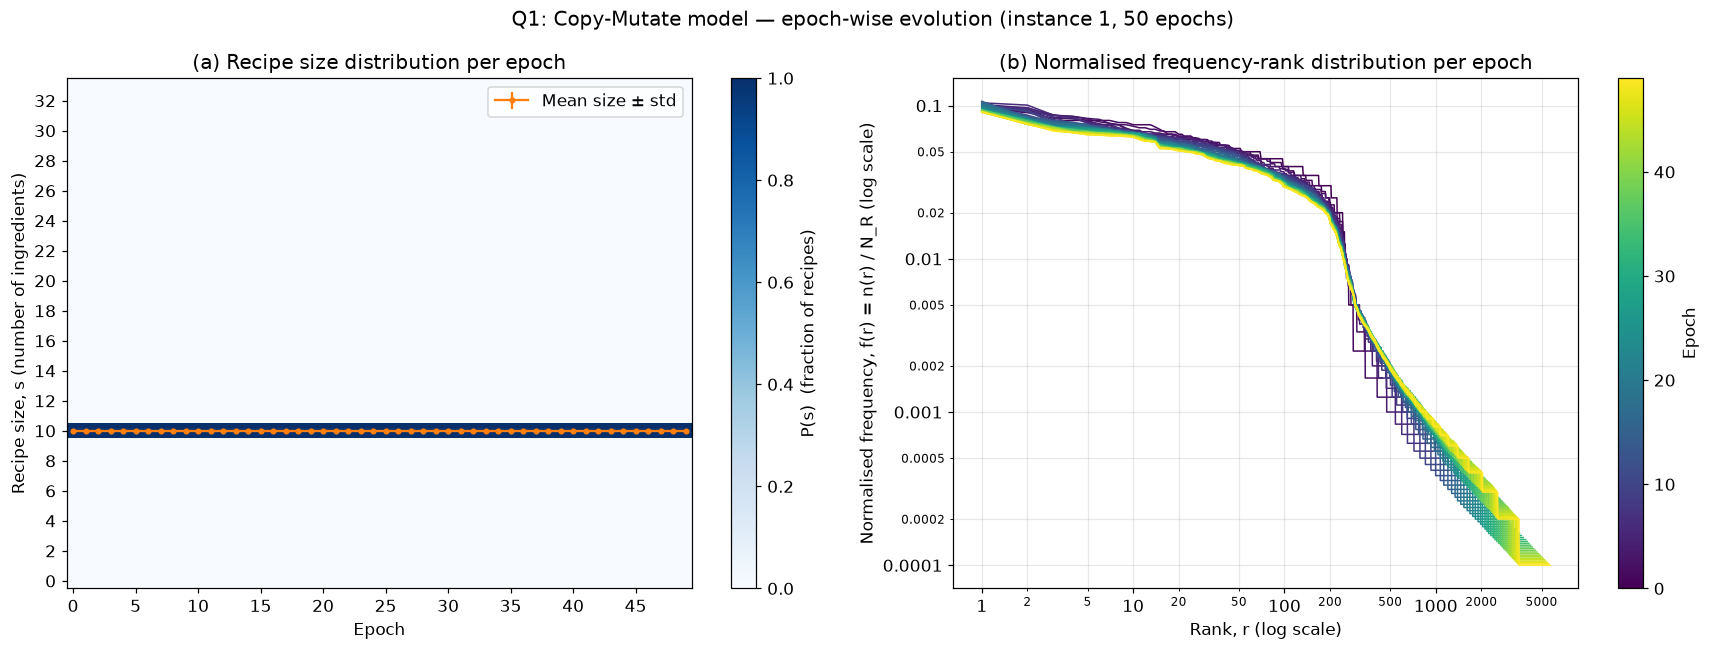

Epoch | #recipes | mean size | std size | #ingredients used
    0 |      200 |     10.00 |     0.00 | 253
    1 |      400 |     10.00 |     0.00 | 343
    2 |      600 |     10.00 |     0.00 | 444
    3 |      800 |     10.00 |     0.00 | 551
    4 |     1000 |     10.00 |     0.00 | 660
    5 |     1200 |     10.00 |     0.00 | 771
    6 |     1400 |     10.00 |     0.00 | 876
    7 |     1600 |     10.00 |     0.00 | 983
    8 |     1800 |     10.00 |     0.00 | 1102
    9 |     2000 |     10.00 |     0.00 | 1209
   10 |     2200 |     10.00 |     0.00 | 1312
   11 |     2400 |     10.00 |     0.00 | 1429
   12 |     2600 |     10.00 |     0.00 | 1531
   13 |     2800 |     10.00 |     0.00 | 1649
   14 |     3000 |     10.00 |     0.00 | 1772
   15 |     3200 |     10.00 |     0.00 | 1884
   16 |     3400 |     10.00 |     0.00 | 2000
   17 |     3600 |     10.00 |     0.00 | 2100
   18 |     3800 |     10.00 |     0.00 | 2208
   19 |     4000 |     10.00 |     0.00 | 2336
   20 | 

In [14]:
_, history = evolve_cuisine(SEEDS[0], record_epochs=True)
epochs = sorted(history)
P_mat  = np.array([size_distribution(history[e], MAX_SIZE)[0] for e in epochs]).T
means  = np.array([np.mean([len(r) for r in history[e]]) for e in epochs])
stds   = np.array([np.std([len(r) for r in history[e]]) for e in epochs])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

im = ax1.imshow(P_mat, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                extent=[epochs[0] - 0.5, epochs[-1] + 0.5, -0.5, MAX_SIZE + 0.5])
ax1.errorbar(epochs, means, yerr=stds, fmt="o-", ms=3, color="tab:orange", label="Mean size ± std")
fig.colorbar(im, ax=ax1, label="P(s)  (fraction of recipes)")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Recipe size, s (number of ingredients)")
ax1.set_title("(a) Recipe size distribution per epoch")
ax1.set_xticks(range(0, epochs[-1] + 1, 5)); ax1.set_yticks(range(0, MAX_SIZE + 1, 2))
ax1.legend(loc="upper right")

cmap = plt.cm.viridis
norm = plt.Normalize(epochs[0], epochs[-1])
for e in epochs:
    f = frequency_rank(history[e])
    ax2.plot(np.arange(1, len(f) + 1), f, color=cmap(norm(e)), lw=1)
ax2.set_xscale("log"); ax2.set_yscale("log"); label_log_axes(ax2)
ax2.set_xlabel("Rank, r (log scale)"); ax2.set_ylabel("Normalised frequency, f(r) = n(r) / N_R (log scale)")
ax2.set_title("(b) Normalised frequency-rank distribution per epoch"); ax2.grid(which="both", alpha=0.3)
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax2, label="Epoch")

fig.suptitle(f"Q1: Copy-Mutate model — epoch-wise evolution (instance 1, {len(epochs)} epochs)")
fig.tight_layout()
fig.savefig("Q1_Epochwise_RecipeSize_and_FrequencyRank.png", dpi=300, bbox_inches="tight"); plt.show()

print("Epoch | #recipes | mean size | std size | #ingredients used")
for e in epochs:
    used = len(set().union(*history[e]))
    print(f"{e:5d} | {len(history[e]):8d} | {means[e]:9.2f} | {stds[e]:8.2f} | {used}")

## Observations

Recipe size stays 10 in all 50 epochs with std 0, this is expected since in Q1 we only replace ingredients and never add or remove so size cant change. The number of ingredients used goes from 253 at epoch 0 to 5688 at epoch 49 so the tail of the frequency rank curve keeps getting longer. The top of the curve gets slightly flatter, f(1) goes from around 0.10 to 0.09. There is also a sharp drop near rank 250, this is because the first 253 ingredients are there from the start and keep getting copied so they stay a lot more common then the ones that come later.

## Running 5 instances

We run the whole evolution 5 times with different seeds, each run ends with 9988 recipes same as the real cuisine.

In [15]:
results = []
for k, seed in enumerate(SEEDS[:N_INSTANCES], 1):
    cuisine, _ = evolve_cuisine(seed)
    results.append(cuisine)
    print(f"Instance {k} (seed={seed}): {len(cuisine)} recipes, "
          f"{len(set().union(*cuisine))} distinct ingredients used")

Instance 1 (seed=11): 9988 recipes, 5688 distinct ingredients used
Instance 2 (seed=22): 9988 recipes, 5627 distinct ingredients used
Instance 3 (seed=33): 9988 recipes, 5642 distinct ingredients used
Instance 4 (seed=44): 9988 recipes, 5630 distinct ingredients used
Instance 5 (seed=55): 9988 recipes, 5641 distinct ingredients used


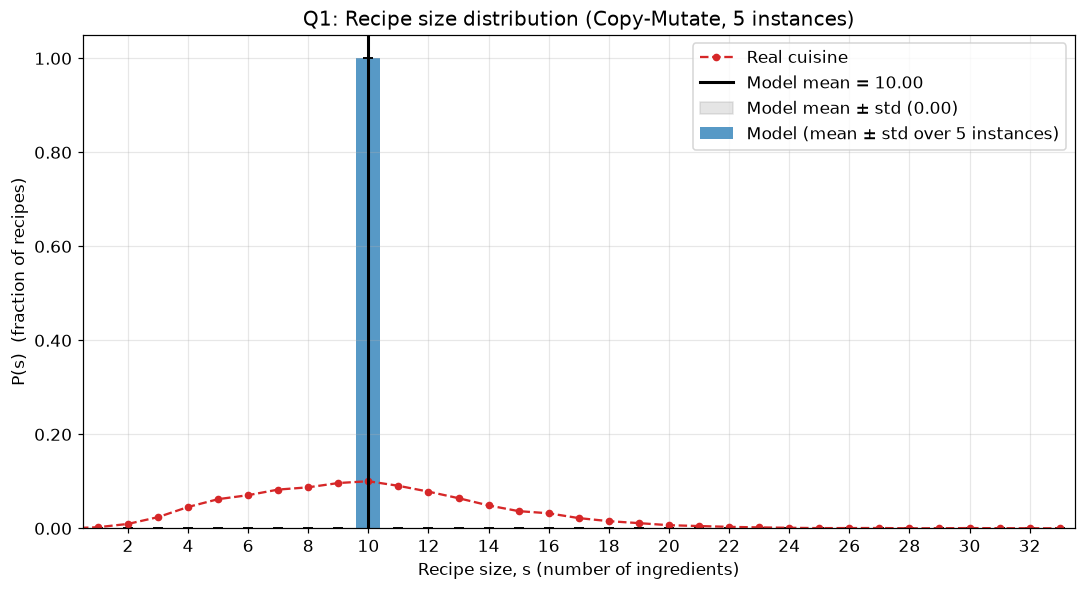

Saved Q1_Recipe_Size_Distribution.png | model size mean = 10.00, std = 0.00 | real mean = 10.00, std = 4.20


In [16]:
plot_size_distribution(results, "Q1: Recipe size distribution (Copy-Mutate, 5 instances)",
                       "Q1_Recipe_Size_Distribution.png")

## Recipe size observations

All recipes in all 5 runs have size 10 so mean is 10.00 and std is 0.00. The real cuisine also has mean 10.00 but its std is 4.20 and sizes go from 1 to 33. So the simple model gets the average size right but not the spread, which is why addition and deletion is needed in Q2.

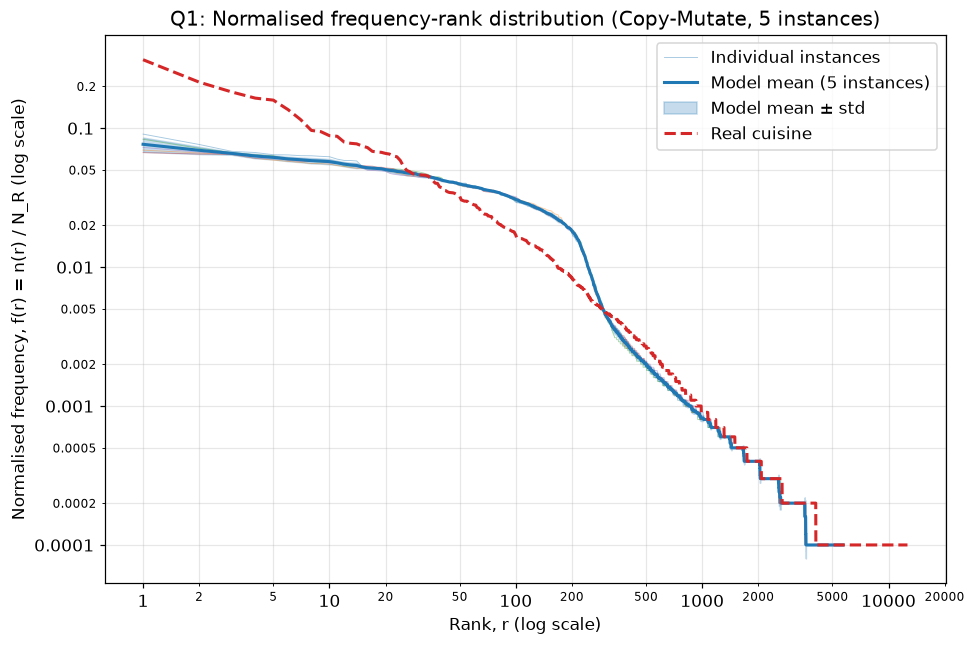

Saved Q1_Frequency_Rank_Distribution.png


In [17]:
plot_frequency_rank(results, "Q1: Normalised frequency-rank distribution (Copy-Mutate, 5 instances)",
                    "Q1_Frequency_Rank_Distribution.png")

## Frequency rank observations

The 5 runs are almost same and the std band is very thin so the result doesnt depend much on the seed. The model curve is flat for the top 250 or so ranks and then drops sharply, while the real curve goes down more smoothly. The top ingredient in the model is in about 7.7% of recipes (f(1) = 0.077) but in real data the top one which is garlic is in 31% of recipes. The model also uses only about 5646 ingredients compared to 12641 in real data. So only random replacement does not give the few very popular ingredients that a real cuisine has.

In [18]:
summarise(results, "Q1")

Q1
  recipe size        : mean = 10.00, std = 0.00   (real: 10.00, 4.20)
  f(1) top ingredient: 0.077 ± 0.009   (real: 0.311)
  ingredients used   : 5646 ± 22   (real: 12641)


## Conclusion

The copy mutate model with only replacement keeps every recipe at the same size so it cant match the real size distribution. The frequency rank has a long tail but the top ingredients are not nearly as popular as the real ones. We try to improve both of these in Q2 and Q3.